# 03 – Analyse en composantes principales (ACP) et variables clés

Le brief demande une **ACP sur le jeu Agriculture Crop Yield** pour identifier les variables clés, puis de **valider** cette analyse avec le jeu Crop Yield Prediction (FAO).

### L'ACP en deux phrases
L'ACP résume un tableau de plusieurs variables numériques en quelques **axes** (combinaisons des variables) qui concentrent le plus possible de l'information (la variance). Si plusieurs variables évoluent ensemble, elles se retrouvent sur le même axe : on voit ainsi quelles variables **vont de pair**.

### Ce qu'elle peut et ne peut pas dire
- L'ACP est **non supervisée** : elle ne sait pas ce qu'est la cible. Pour voir quelles variables vont de pair **avec le rendement**, on l'inclut comme variable active et on lit le **cercle des corrélations**.
- Elle ne traite que des variables **numériques**. Pour les variables qualitatives (culture, région, sol, météo), on mesure leur lien avec le rendement par le **rapport de corrélation η²** (part de la variance du rendement expliquée par la variable, entre 0 et 1).
- Les variables sont **centrées-réduites** (ACP normée) : sinon la pluie (en centaines de mm) écraserait les variables oui/non.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from agritech_crop_reco.analysis import eta_squared, pca_correlations
from agritech_crop_reco.config import PROJECT_ROOT, load_settings
from agritech_crop_reco.data.clean import clean_crop_yield
from agritech_crop_reco.data.load import load_crop_yield
from agritech_crop_reco.data.merge import CONSOLIDATED_FILE

settings = load_settings()
FIG_DIR = PROJECT_ROOT / "reports" / "figures"
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.float_format", "{:,.3f}".format)


def save(fig, name):
    fig.savefig(FIG_DIR / f"03_{name}.png", dpi=120, bbox_inches="tight")


def scree(explained, title, ax):
    explained.mul(100).plot.bar(ax=ax, color="tab:green")
    ax.axhline(100 / len(explained), ls="--", color="grey", label="part si variables indépendantes")
    ax.set_ylabel("% de variance")
    ax.set_title(title)
    ax.legend(fontsize=8)


def correlation_circle(loadings, explained, ax, x="F1", y="F2", highlight=None):
    ax.add_patch(plt.Circle((0, 0), 1, fill=False, color="grey"))
    for var, (lx, ly) in loadings[[x, y]].iterrows():
        color = "tab:red" if var == highlight else "tab:blue"
        ax.arrow(0, 0, lx, ly, color=color, head_width=0.03, length_includes_head=True)
        ax.annotate(var, (lx * 1.08, ly * 1.08), color=color, ha="center", fontsize=9)
    ax.axhline(0, color="grey", lw=0.5)
    ax.axvline(0, color="grey", lw=0.5)
    ax.set(
        xlim=(-1.15, 1.15),
        ylim=(-1.15, 1.15),
        aspect="equal",
        xlabel=f"{x} ({explained[x]:.1%})",
        ylabel=f"{y} ({explained[y]:.1%})",
    )

## 1. Agriculture Crop Yield (Kaggle)

On utilise le jeu nettoyé à l'étape 02 (rendements ≤ 0 retirés). Variables numériques : pluie, température, durée de culture, engrais et irrigation (codés 0/1).

In [2]:
crop = clean_crop_yield(load_crop_yield())
TARGET = "Yield_tons_per_hectare"
ACTIVE = [
    "Rainfall_mm",
    "Temperature_Celsius",
    "Days_to_Harvest",
    "Fertilizer_Used",
    "Irrigation_Used",
]
print(f"{len(crop):,} parcelles")

999,769 parcelles


### 1.1 ACP des seules variables explicatives

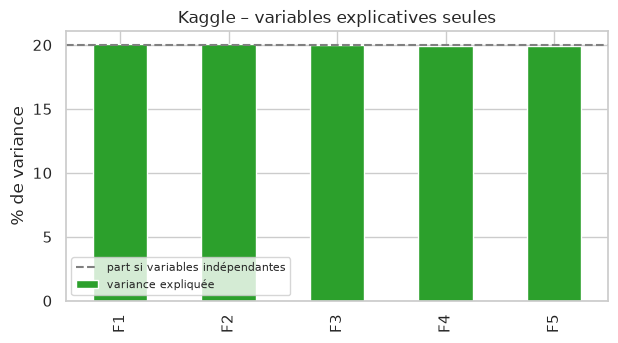

,F1,F2,F3,F4,F5
variance expliquée,0.201,0.201,0.200,0.199,0.199


In [3]:
explained_x, loadings_x = pca_correlations(crop, ACTIVE)
fig, ax = plt.subplots(figsize=(7, 3.5))
scree(explained_x, "Kaggle – variables explicatives seules", ax)
save(fig, "kaggle_scree_features")
plt.show()
explained_x.to_frame().T

**Lecture.** Chaque axe porte **exactement 20 %** de la variance, c'est-à-dire 1/5 : c'est la signature de variables **totalement indépendantes** entre elles (aucune ne « va avec » une autre). Conséquences :
- **aucune redondance** : on ne peut supprimer aucune variable explicative sous prétexte qu'une autre porte la même information ;
- les axes n'ont **pas de sens** ici (quand toutes les valeurs propres sont égales, leur orientation est arbitraire) : il ne faut pas interpréter leurs coordonnées.

C'est cohérent avec le caractère **synthétique** du jeu (chaque variable tirée au hasard, indépendamment des autres).

### 1.2 ACP avec le rendement comme variable active

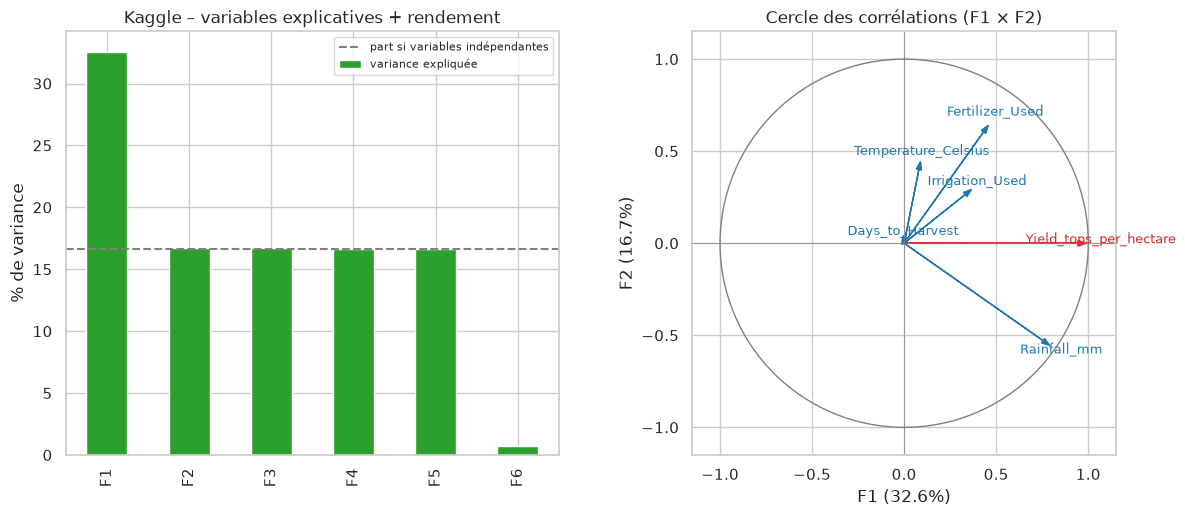

,F1,F2,F3,F4,F5,F6
Rainfall_mm,0.790,-0.550,-0.210,0.080,0.060,-0.120
Temperature_Celsius,0.090,0.440,-0.650,0.050,0.610,-0.010
Days_to_Harvest,-0.010,0.040,0.290,0.930,0.200,-0.000
Fertilizer_Used,0.460,0.640,-0.050,0.120,-0.600,-0.070
Irrigation_Used,0.370,0.290,0.670,-0.320,0.470,-0.060
Yield_tons_per_hectare,0.990,-0.000,0.000,0.000,0.000,0.150


In [4]:
explained_y, loadings_y = pca_correlations(crop, ACTIVE + [TARGET])
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
scree(explained_y, "Kaggle – variables explicatives + rendement", axes[0])
correlation_circle(loadings_y, explained_y, axes[1], highlight=TARGET)
axes[1].set_title("Cercle des corrélations (F1 × F2)")
save(fig, "kaggle_pca_with_yield")
plt.show()
loadings_y.round(2)

**Lecture.**
- Le **premier axe F1** (≈ 33 % de la variance, contre 17 % attendus au hasard) est l'**axe du rendement** : le rendement y est corrélé à 0,99.
- Les variables qui **tirent F1** dans la même direction que le rendement sont, dans l'ordre : la **pluie** (≈ 0,79), l'**engrais** (≈ 0,46) et l'**irrigation** (≈ 0,37). La **température** (≈ 0,09) et la **durée de culture** (≈ 0) n'y participent quasiment pas.
- Le **dernier axe F6** ne porte que ≈ 0,7 % de la variance : le rendement est presque entièrement une **combinaison des autres variables**. C'est cohérent avec le R² ≈ 0,91 d'une simple régression linéaire mesuré en exploration.

### 1.3 Variables qualitatives : rapport de corrélation η²

In [5]:
QUALI = ["Crop", "Region", "Soil_Type", "Weather_Condition"]
eta_kaggle = pd.Series({col: eta_squared(crop[col], crop[TARGET]) for col in QUALI}, name="η²")
eta_kaggle.to_frame().style.format("{:.6f}")

,η²
Crop,0.000006
Region,0.000003
Soil_Type,0.000002
Weather_Condition,0.000001


**Lecture.** Les η² sont de l'ordre de **0,000001** : la culture, la région, le type de sol et la météo expliquent **0 %** de la variance du rendement dans ce jeu. L'ACP et η² concordent : dans le jeu Kaggle, le rendement dépend de **trois leviers**, pluie, engrais, irrigation, et de rien d'autre de mesurable.

## 2. Validation sur le jeu FAO (dataset consolidé)

On reprend la même démarche sur les 13 130 observations réelles du dataset consolidé. Deux transformations, justifiées par l'EDA :
- **rendement en log** : sa distribution est très asymétrique (une ACP est sensible aux valeurs extrêmes) ;
- **pesticides en log** : même raison, quelques pays dépassent 100 000 tonnes.

In [6]:
fao = pd.read_csv(settings.processed_dir / CONSOLIDATED_FILE)
fao["log_rendement"] = np.log(fao["yield_t_ha"])
fao["log_pesticides"] = np.log1p(fao["pesticides_tonnes"])

eta_fao = pd.Series(
    {
        "crop": eta_squared(fao["crop"], fao["log_rendement"]),
        "country": eta_squared(fao["country"], fao["log_rendement"]),
    },
    name="η² (log rendement)",
)
eta_fao.to_frame()

,η² (log rendement)
crop,0.581
country,0.228


**Lecture.** À elle seule, **la culture explique ≈ 58 % de la variance** du rendement (en log), alors qu'elle n'expliquait rien dans Kaggle. Le pays en explique aussi une part importante : il résume tout ce qui n'est pas mesuré (sols, mécanisation, savoir-faire…).

Pour étudier l'effet du climat **sans qu'il soit masqué par l'effet culture**, on construit un **rendement relatif** : l'écart (en log) entre le rendement observé et le rendement moyen de la culture. Une valeur de +0,3 signifie « environ 35 % au-dessus de la moyenne de sa culture ».

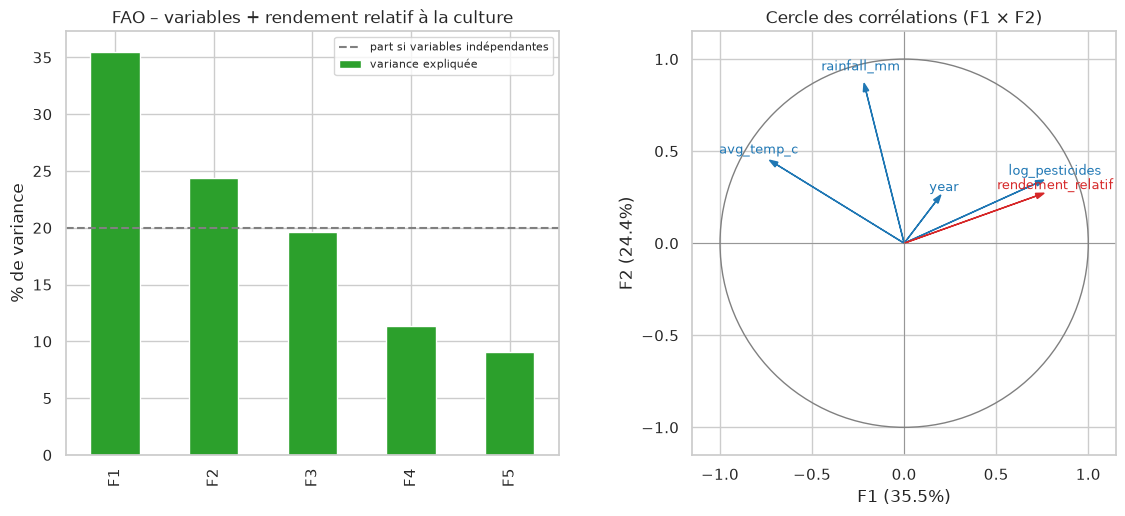

,F1,F2,F3,F4,F5
rainfall_mm,-0.220,0.870,-0.240,-0.160,-0.330
log_pesticides,0.760,0.340,-0.210,-0.330,0.400
avg_temp_c,-0.730,0.450,0.090,0.280,0.420
year,0.200,0.260,0.930,-0.130,-0.040
rendement_relatif,0.760,0.270,-0.020,0.580,-0.080


In [7]:
fao["rendement_relatif"] = fao["log_rendement"] - fao.groupby("crop")["log_rendement"].transform(
    "mean"
)
FAO_ACTIVE = ["rainfall_mm", "log_pesticides", "avg_temp_c", "year"]

explained_f, loadings_f = pca_correlations(fao, FAO_ACTIVE + ["rendement_relatif"])
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
scree(explained_f, "FAO – variables + rendement relatif à la culture", axes[0])
correlation_circle(loadings_f, explained_f, axes[1], highlight="rendement_relatif")
axes[1].set_title("Cercle des corrélations (F1 × F2)")
save(fig, "fao_pca_relative_yield")
plt.show()
loadings_f.round(2)

In [8]:
# Corrélation directe de chaque variable avec le rendement relatif (complément de lecture)
fao[FAO_ACTIVE].corrwith(fao["rendement_relatif"]).sort_values(key=abs, ascending=False).to_frame(
    "r"
)

,r
log_pesticides,0.451
avg_temp_c,-0.304
year,0.133
rainfall_mm,0.008


**Lecture.** Une fois l'effet culture retiré :
- le **premier axe F1** réunit le **rendement relatif** (≈ 0,76) et les **pesticides** (≈ 0,76), face à la **température** (≈ −0,73) : d'un côté des pays tempérés à agriculture intensive et aux rendements élevés, de l'autre des pays chauds moins intensifs aux rendements plus faibles, **à culture égale** ;
- en corrélation directe : pesticides r ≈ +0,45, température r ≈ −0,30, année r ≈ +0,13 (progrès techniques) ;
- la **pluie annuelle n'a aucun lien** avec le rendement relatif (r ≈ 0) : elle forme à elle seule l'axe F2, indépendant du rendement ;
- le rendement relatif reste aussi porté par un axe propre (F4 ≈ 0,58) : une part de ses variations n'est expliquée par **aucune** de ces variables (sols, mécanisation, savoir-faire… résumés par le pays).

## 3. Synthèse : les variables clés

### Ce que la validation confirme et ce qu'elle nuance

| Variable | Jeu Kaggle (simulé) | Jeu FAO (réel) | Verdict |
|---|---|---|---|
| **Culture** | aucun effet (η² ≈ 0) | **1er facteur** (η² ≈ 0,58) | variable clé n° 1, **seul le jeu FAO permet de la mesurer** |
| **Engrais** | effet fort (+45 %) | non mesuré | variable clé de pratique (source : Kaggle) |
| **Irrigation** | effet fort (+36 %) | non mesuré | variable clé de pratique (source : Kaggle) |
| **Pluie** | **1er levier** (r ≈ 0,77) | aucun lien (r ≈ 0) | importante à l'échelle de la parcelle ; la moyenne nationale annuelle FAO est trop grossière pour la capter |
| **Pesticides** | non mesuré | lien positif le plus fort | indicateur d'**intensification** du pays plutôt qu'effet direct |
| **Température** | effet faible | lien **négatif** | effet réel mais modéré : pays chauds = rendements plus faibles à culture égale |
| Durée de culture, région, sol, météo | aucun effet | non mesurés | non retenues |

### Ce que cela implique pour la suite
1. **Modèle de rendement (étape 2)** : entraîné sur le dataset consolidé FAO avec la **culture**, la **température**, les **pesticides**, la **pluie** (et l'année, à arbitrer). La culture devant interagir avec le climat (effets différents selon la culture, vu en EDA), les modèles à base d'arbres sont de bons candidats.
2. **Ajustement pratiques** : engrais et irrigation appliqués **après** la prédiction, via les gains mesurés sur Kaggle.
3. **Aucune réduction de dimension** n'est utile : peu de variables, pas de redondance. L'ACP sert ici à **comprendre**, pas à construire les entrées du modèle.

### Pour un public non technique
> Le **choix de la culture** est de loin ce qui compte le plus : à conditions égales, les rendements varient d'un facteur 10 d'une culture à l'autre. Viennent ensuite les **pratiques** : utiliser de l'engrais et irriguer augmentent nettement le rendement. Le **climat** compte aussi : les régions chaudes obtiennent en moyenne des rendements plus faibles. Enfin, les pays qui utilisent le plus de pesticides ont de meilleurs rendements, mais c'est surtout le signe d'une agriculture plus modernisée dans son ensemble, pas la preuve qu'ajouter des pesticides suffit.